In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import h5py
from ipywidgets import HBox, VBox

No windowing system present. Using surfaceless platform
No config found!
No config found!


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
✅ (default) | Tesla V100-SXM2-32GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | Tesla V100-SXM2-32GB/PCIe/SSE2 | Unknown | OpenGL | 


In [2]:
import scipy
import scipy.integrate
from pydmd import DMD, BOPDMD
from pydmd.preprocessing import hankel_preprocessing
from pydmd.plotter import plot_modes_2D, plot_summary

In [3]:
movie = tifffile.imread("./data_endoscope.tif")

In [4]:
iw = fpl.ImageWidget(movie, cmap="gnuplot2")
iw.show()

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [5]:
movie.shape

(1000, 128, 128)

In [6]:
movie = movie[:3_000].copy()

In [7]:
X = movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2])

In [8]:
X.shape

(1000, 16384)

In [128]:
delay = 2
t = np.arange(0, movie.shape[0])
delay_t = t[: -delay + 1]

dmd = BOPDMD(
    svd_rank=15, num_trials=0, eig_constraints={"imag", "conjugate_pairs"}
)
delay_dmd = hankel_preprocessing(dmd, d=delay)
delay_dmd.fit(X.T, t=delay_t)

In [102]:
dmd.modes.shape

(32768, 3)

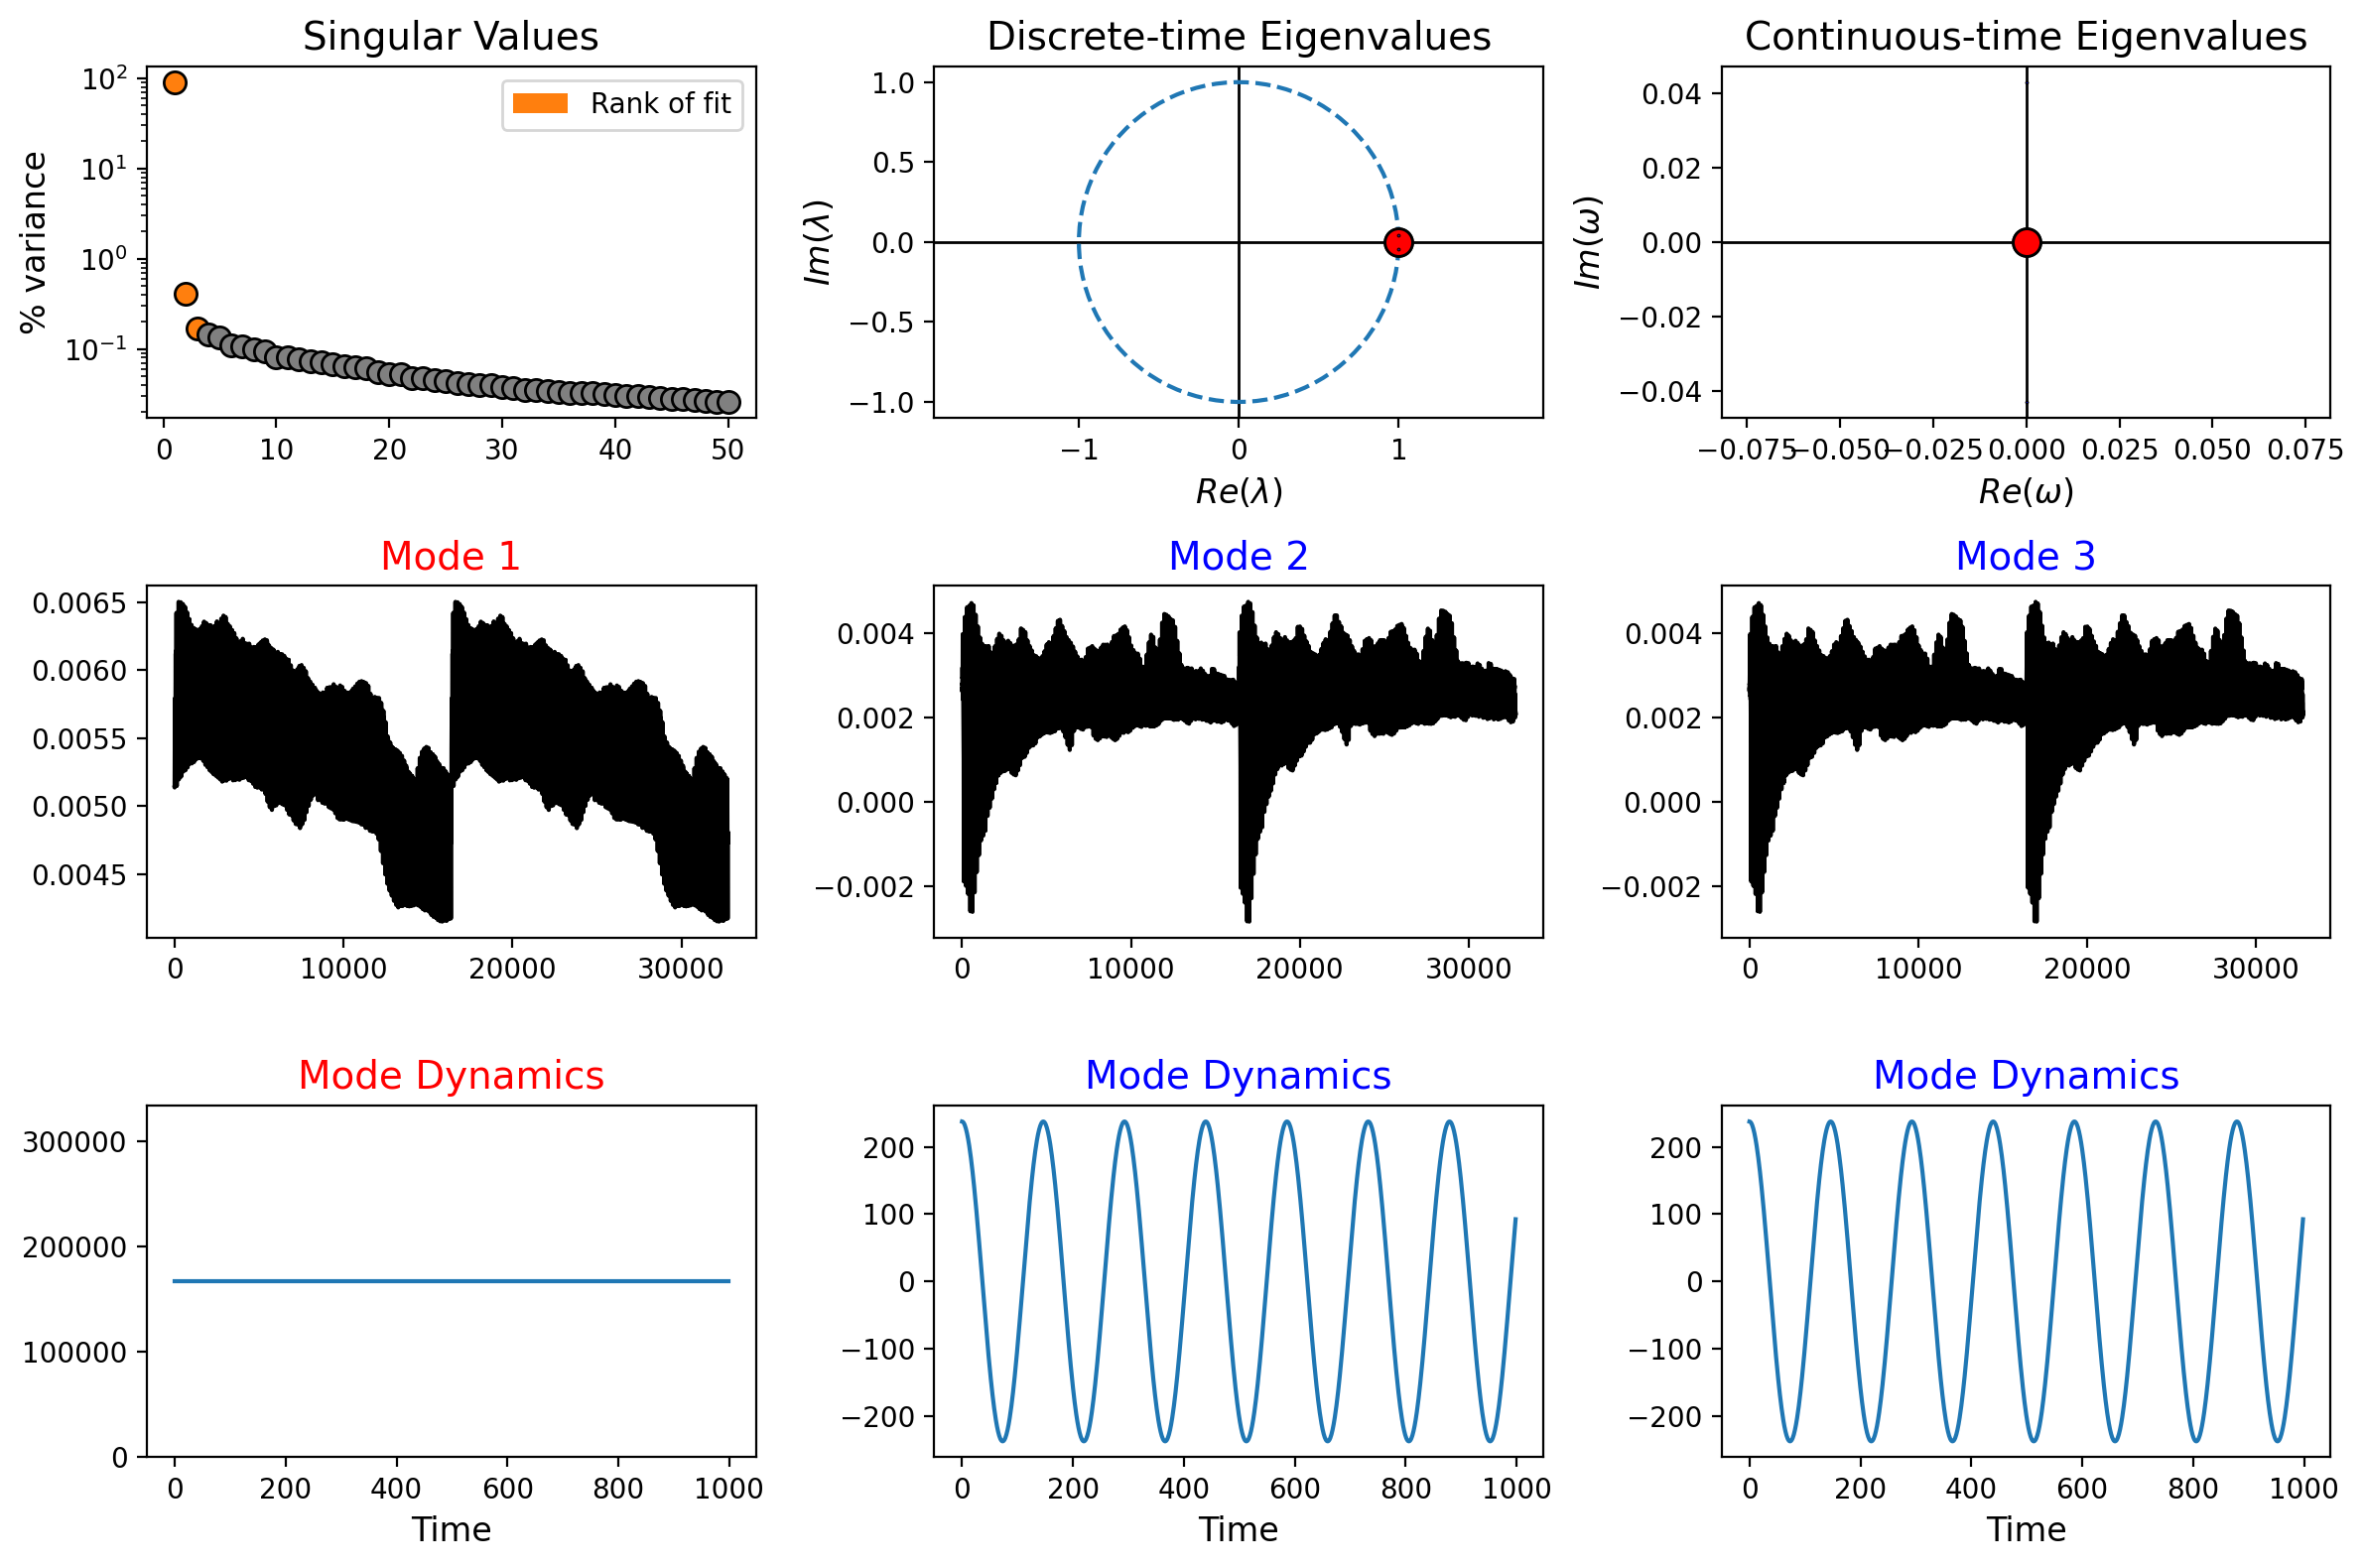

In [103]:
plot_summary(dmd, plot_semilogy=True)

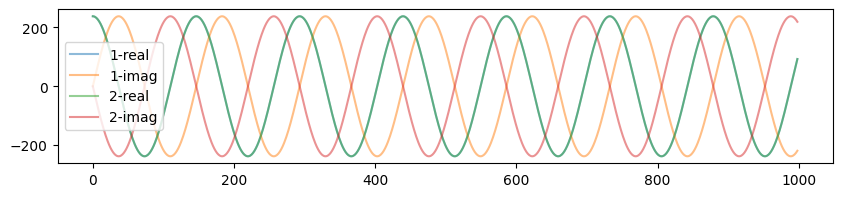

In [104]:
fig = plt.figure(figsize=(10, 2))
plt.plot(dmd.dynamics[1].real, alpha=0.5, label="1-real")
plt.plot(dmd.dynamics[1].imag, alpha=0.5, label="1-imag")
plt.legend()
# plt.show()

# fig = plt.figure(figsize=(10, 2))
plt.plot(dmd.dynamics[2].real, alpha=0.5, label="2-real")
plt.plot(dmd.dynamics[2].imag, alpha=0.5, label="2-imag")
plt.legend()
plt.show()

In [129]:
dmd.modes.shape

(32768, 15)

In [130]:
shape = (128*2, 128)
iw = fpl.ImageWidget([m.reshape(shape).astype(np.float32) for m in dmd.modes.T], cmap="gnuplot2")
iw.show()

/tmp/ipykernel_257618/2801945657.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  iw = fpl.ImageWidget([m.reshape(shape).astype(np.float32) for m in dmd.modes.T], cmap="gnuplot2")


RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [131]:
dmd.reconstructed_data.shape

(32768, 999)

In [132]:
recon = np.dstack([r.reshape(shape).astype(np.float32) for r in dmd.reconstructed_data.T]).T

/tmp/ipykernel_257618/2368579062.py:1: ComplexWarning: Casting complex values to real discards the imaginary part
  recon = np.dstack([r.reshape(shape).astype(np.float32) for r in dmd.reconstructed_data.T]).T


In [133]:
iw = fpl.ImageWidget(np.dstack([r.reshape(shape).astype(np.float32) for r in dmd.reconstructed_data.T]).T.swapaxes(1, 2), cmap="gnuplot2")
iw.show()

/tmp/ipykernel_257618/3922419950.py:1: ComplexWarning: Casting complex values to real discards the imaginary part
  iw = fpl.ImageWidget(np.dstack([r.reshape(shape).astype(np.float32) for r in dmd.reconstructed_data.T]).T.swapaxes(1, 2), cmap="gnuplot2")


RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

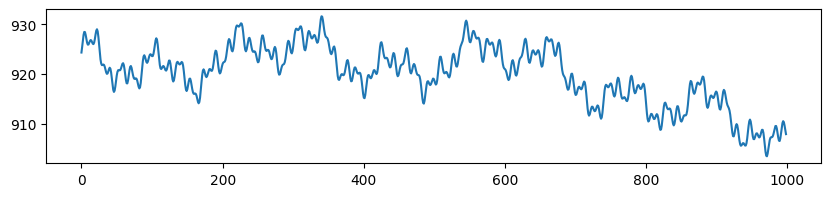

In [134]:
fig = plt.figure(figsize=(10, 2))
plt.plot(recon[..., :128].mean(axis=(1, 2)))

In [135]:
recon.shape

(999, 128, 256)

In [136]:
sub = movie[:-1] - recon[:, :, :128].swapaxes(1, 2)

iw_sub = fpl.ImageWidget([movie, sub], cmap="gnuplot2")
iw_sub.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

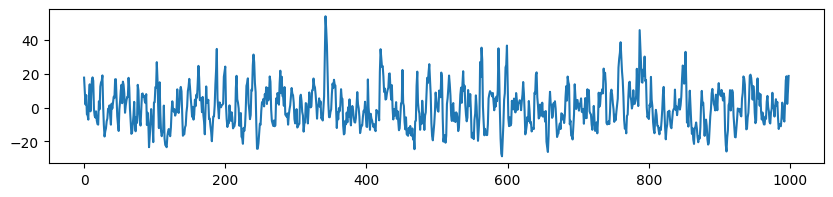

In [138]:
fig = plt.figure(figsize=(10, 2))
plt.plot(sub.mean(axis=(1, 2)))

In [21]:
p = fpl.Plot()
lg = p.add_line(recon[..., :128].mean(axis=(1, 2)))
sel = lg.add_linear_selector()
p.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [42]:
from scipy.sparse.linalg import svds

In [70]:
u, s, v = svds(sub.reshape(999, movie.shape[1] * movie.shape[2]).T)

In [71]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [72]:
iw_regular_svd = fpl.ImageWidget([ui.reshape(movie.shape[1], movie.shape[2]) for ui in u.T], names=[str(i) for i in range(s.size)], cmap="gnuplot2")
iw_regular_svd.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

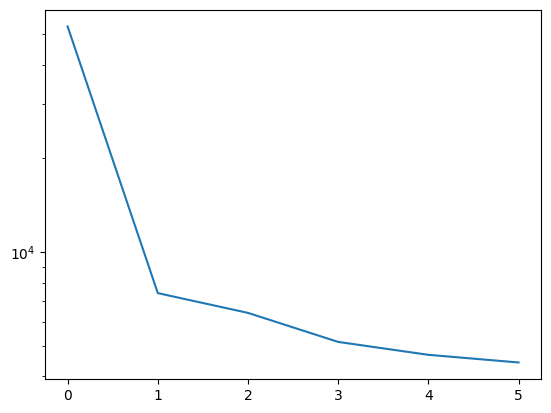

In [73]:
plt.plot(s)
plt.yscale("log")

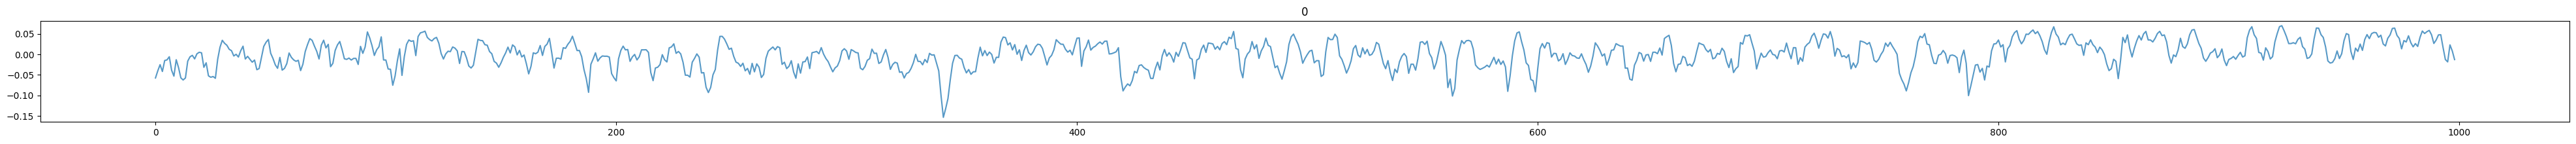

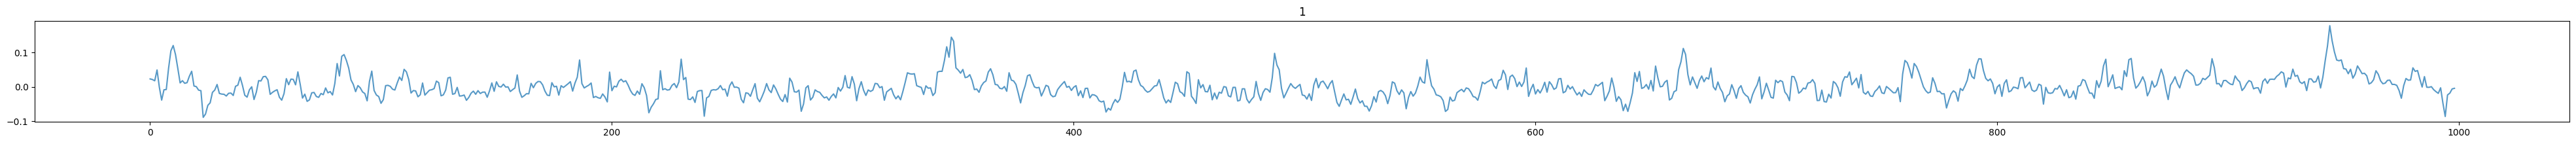

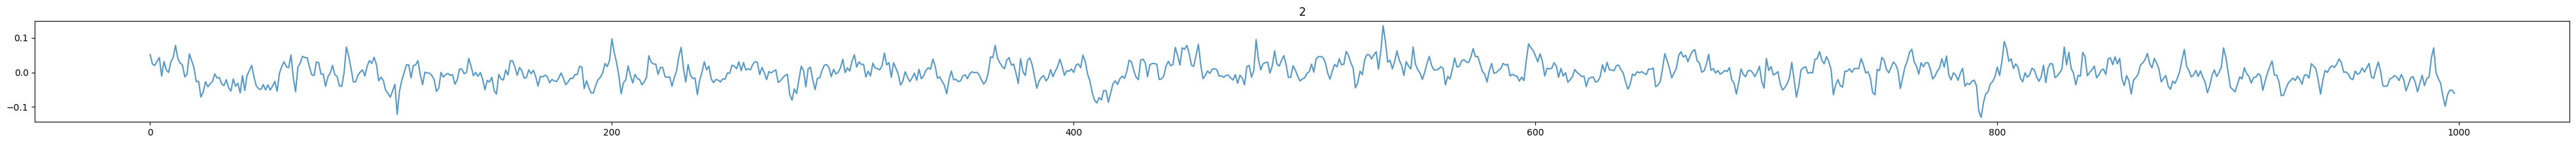

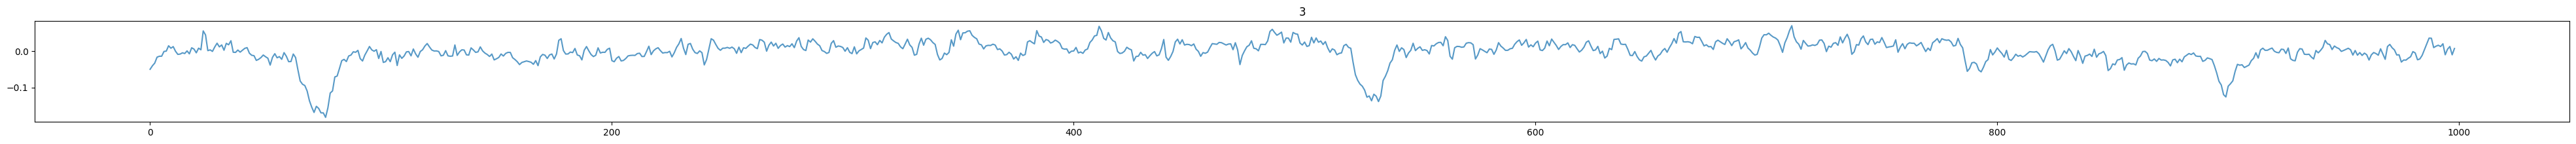

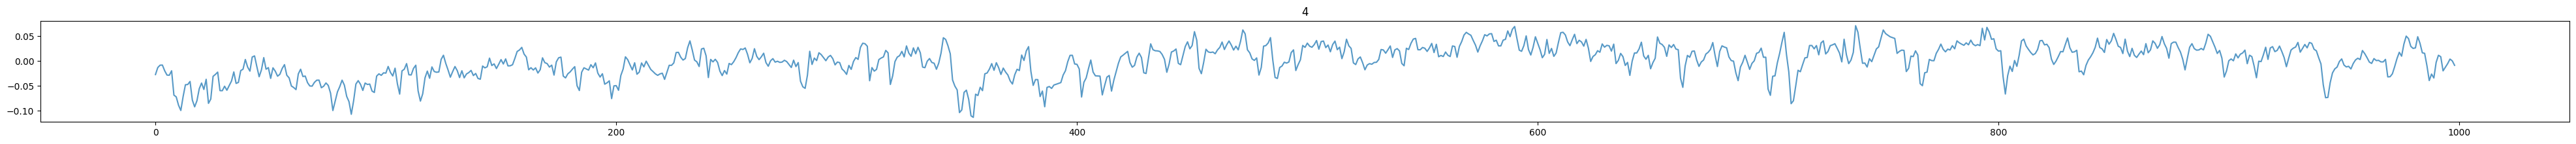

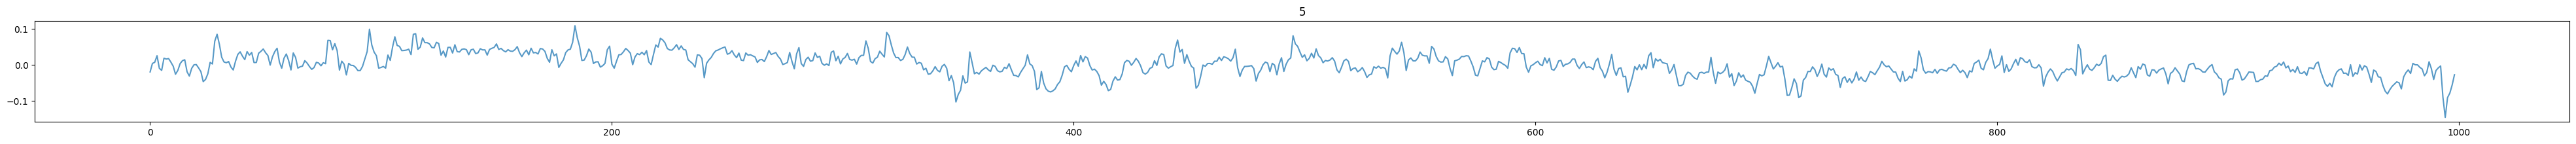

In [74]:
for i, vi in enumerate(v):
    fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    plt.title(i)
    plt.show()
    # if i == 1:
    #     break

In [75]:
u, s, v = svds(movie.reshape(1000, movie.shape[1] * movie.shape[2]).T.astype(np.float32))

In [76]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [77]:
_iw_regular_svd = fpl.ImageWidget([ui.reshape(movie.shape[1], movie.shape[2]) for ui in u.T], names=[str(i) for i in range(s.size)], cmap="gnuplot2")
_iw_regular_svd.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

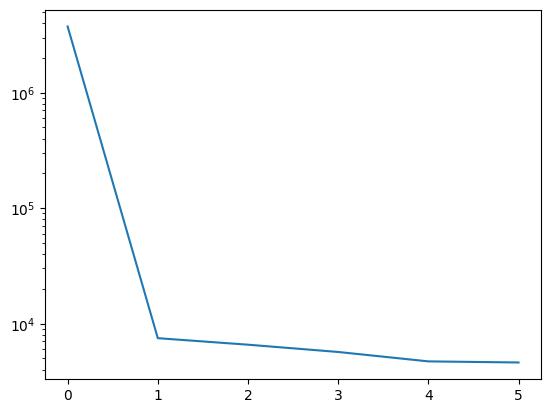

In [57]:
plt.plot(s)
plt.yscale("log")

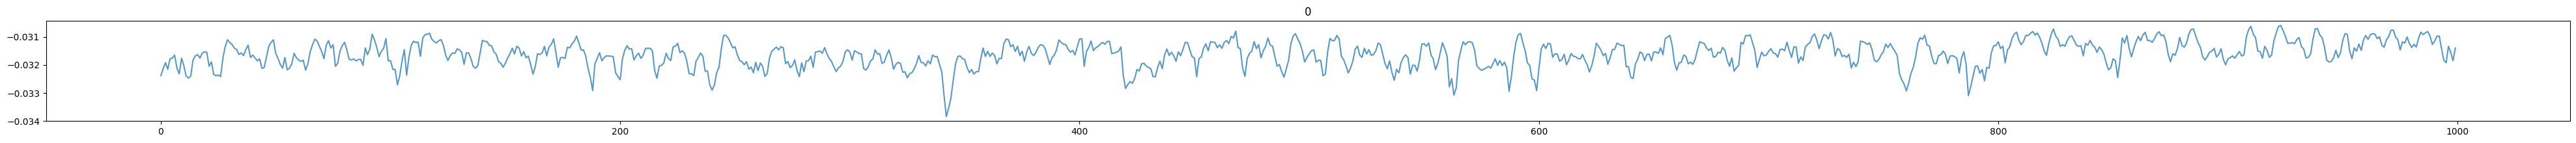

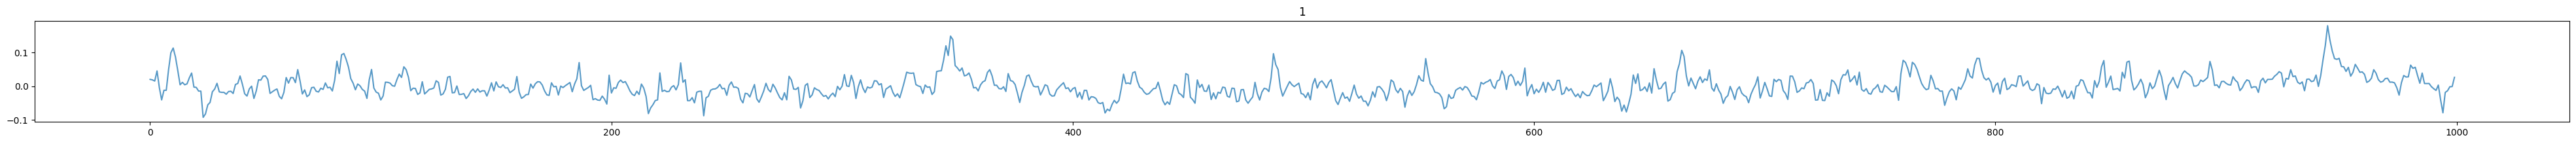

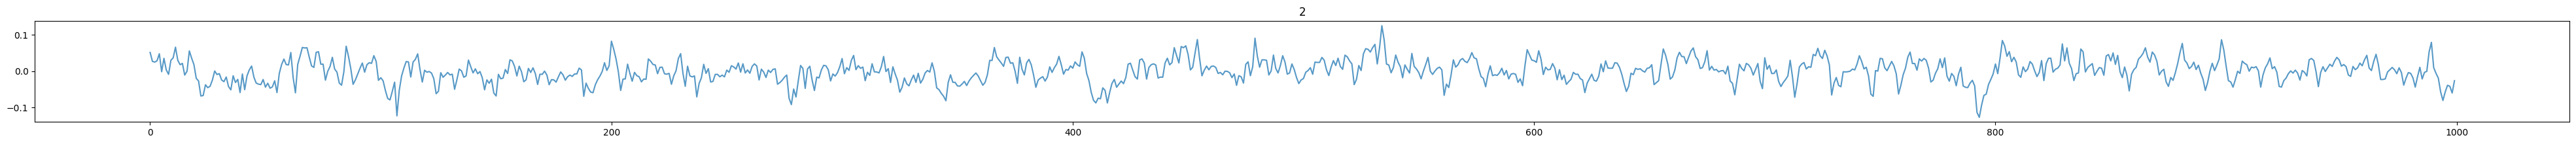

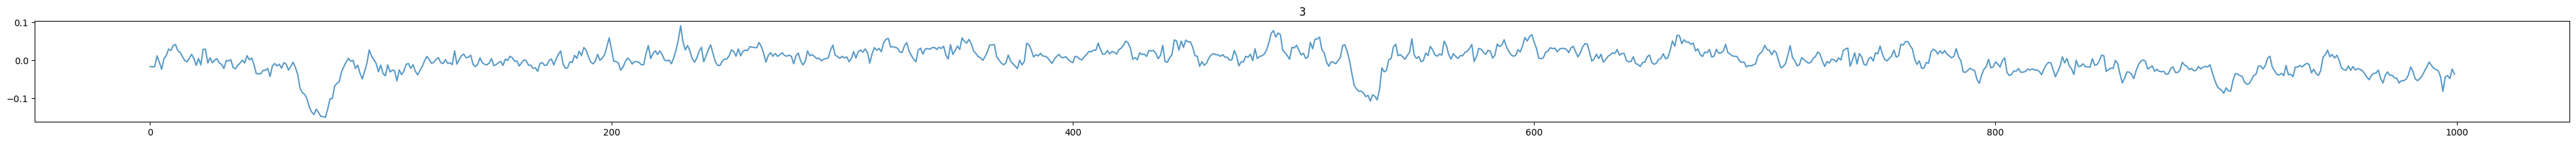

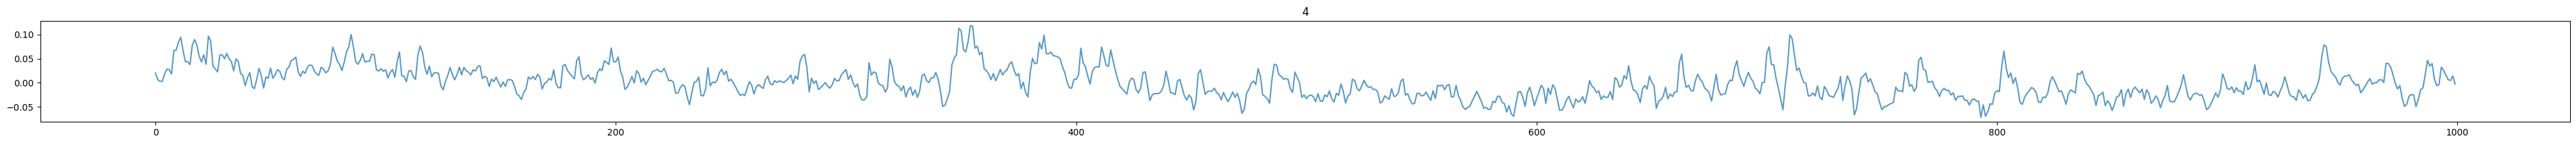

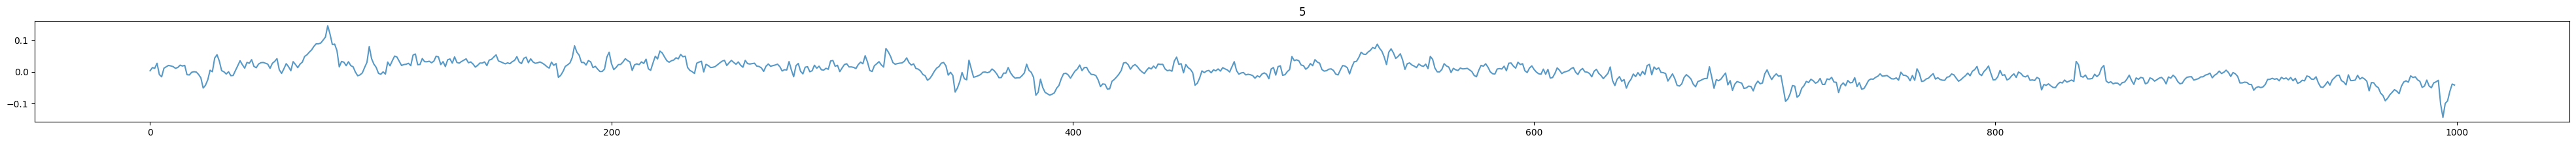

In [58]:
for i, vi in enumerate(v):
    fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    plt.title(i)
    plt.show()
    # if i == 1:
    #     break

In [36]:
sel.step = 1

In [22]:
sel.add_ipywidget_handler(iw_sub.sliders["t"])

In [17]:
movie_mean = movie.mean(axis=(1, 2))

In [18]:
from tslearn.preprocessing import TimeSeriesScalerMinMax

/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


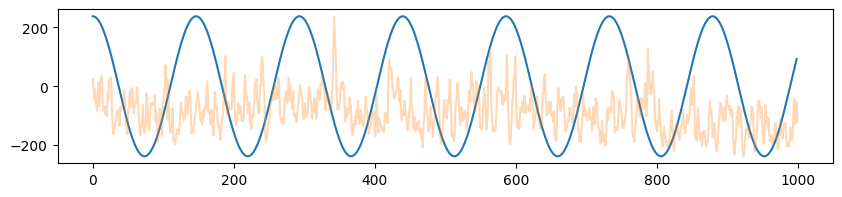

/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/mnt/home/kkolar/venvs/mescore/lib/python3.11/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


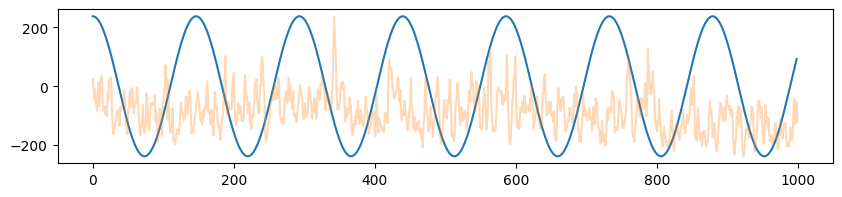

In [19]:
for t in dmd.dynamics[1:]:
    fig = plt.figure(figsize=(10, 2))
    plt.plot(t)
    plt.plot(TimeSeriesScalerMinMax((t.real.min(), t.real.max())).fit_transform(movie_mean.reshape(1, -1)).ravel(), alpha=0.3)
    plt.show()

In [31]:
np.unique(dmd.dynamics[0])

array([167137.06939133+0.j])

In [78]:
class TdSVD:
    def __init__(
        self,
        movie: np.ndarray,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        self.movie_mean = movie.mean(axis=0)
        
        frame = movie[0]
        self.xdim, self.ydim = frame.shape[0], frame.shape[1]
        
        n_pixels = self.xdim * self.ydim
        n_timepoints = movie.shape[0]
        
        self.A = np.zeros(shape=(n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32)
        A_ixs = np.zeros(n_pixels * n_time_steps)
        
        for pixel_ix, (x, y) in tqdm(enumerate(product(range(self.xdim), range(self.ydim))), total=n_pixels):
            for step in range(n_time_steps):
                self.A[(n_time_steps * pixel_ix) + step] = np.roll(movie[:, x, y], shift=-delay * step)[:-n_time_steps]

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        t0 = time()
        self.U, self.S, self.V = svds(self.A, k=k, **kwargs)
        self.U = self.U[:, ::-1]
        self.S = self.S[::-1]
        self.V = self.V[::-1, :]
        t1 = time()
        print(f"svd took: {t1 - t0:.02f} sec")

    def get_spatial(self):
        """
        Returns
        -------
        np.ndarray
            [n_time_steps, k, ydim, xdim]
        """
        return np.array([self.U.reshape((self.xdim, self.ydim, self.n_time_steps, self.k))[..., i, :].transpose(2, 0, 1) for i in range(self.n_time_steps)])

In [84]:
td_svd = TdSVD(
    movie=sub,
    n_time_steps=10,
    delay=1,
)

100%|█████████████████████████████████████████████████████████████████████████████████████████| 16384/16384 [00:04<00:00, 3708.89it/s]


In [85]:
td_svd.fit(k=8)

svd took: 3.29 sec


In [86]:
spatial = td_svd.get_spatial()

In [87]:
spatial.shape

(10, 8, 128, 128)

In [88]:
iw_steps = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw_steps.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [90]:
iw_steps = fpl.ImageWidget(
    data=[spatial[:, k_step] for k_step in range(td_svd.k)],
    names=[f"k-{i}" for i in range(td_svd.k)],
    grid_plot_kwargs={"size": (1500, 400)}
)

plot_lines = fpl.Plot()
plot_lines.docks["right"].size = 70

iw_steps.show()

RFBOutputContext()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…